# ☀️ "○○을 비춰라" 기상 미션 알람 — 스터디 발표용 한 권 정리

> 알람을 끄려면 **"우산을 비춰라!"** 처럼 제시된 물건을 폰 카메라에 비춰야 한다.
> 일어나서 물건을 찾으러 움직이게 만드는 알람. **아무 우산이나** 통과해야 한다.

**데모**: https://rltjr4362.github.io/wakeup-mission/ (아이폰 Safari) · **코드**: https://github.com/rltjr4362/wakeup-mission

이 노트북은 **"무엇을 만들고 → 어떤 방법들이 있었고 → 왜 이걸 골랐고 → 결과가 어땠나"** 순서로 읽는다.
학습은 다시 하지 않고, 앞서 돌린 결과(`runs/`, `data/`)를 불러와 보여 준다.

| 절 | 내용 | 쟁점 (토론거리) |
|---|---|---|
| 1 | 무엇을 만드나 · 성공 기준 | "통과"를 무엇으로 잴까? |
| 2 | 방법 고르기 | 분류? 탐지? 2단계? 제로샷? 클라우드 API? |
| 3 | 데이터 고르기 | 직접 찍기? COCO? Open Images? |
| 4 | EDA | 불균형이 문제였을까? |
| 5 | 원리 — YOLO11n · 전이학습 · 지표 | softmax가 아니라 sigmoid인 이유 |
| 6 | 전체 파이프라인 | |
| 7 | 실험 여정 (기준선 → A/B → C → E) | 왜 이 순서로 실험했나 |
| 8 | 앱으로 만들기 | 네이티브? 웹앱? 서버? |
| 9 | 결과 한눈에 · 한계 · 다음 할 일 | |
| 10 | 스터디 토론 질문 | |

자세한 과정은 원래 노트북에 있다: `wakeup_mission.ipynb`(A·B) · `wakeup_eda.ipynb`(EDA) · `wakeup_clean.ipynb`(C) · `wakeup_v2.ipynb`(E, 지금 앱).

In [1]:
from pathlib import Path
import json, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import cv2
from IPython.display import Image, display, Markdown

plt.rcParams['font.family'] = 'AppleGothic'; plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.width', 160)
import warnings, logging; warnings.filterwarnings('ignore'); logging.getLogger('matplotlib').setLevel(logging.ERROR)

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
import sys; sys.path.insert(0, str(ROOT))
from src import config as C
from src.postprocess import decode, nms, pick_main

KO = [c.ko for c in C.CLASSES13]
KEYS = [c.key for c in C.CLASSES13]
DATA = ROOT / 'data/yolo13_full'      # 실험 E의 전체 사진 세트 (13종 + 네거티브 사진)
RUNS = ROOT / 'runs'
print('클래스 13종:', ' · '.join(f'{c.emoji}{c.ko}' for c in C.CLASSES13))

클래스 13종: 🖱️마우스 · ☂️우산 · 📖책 · 🪥칫솔 · 🧢모자 · 🚪문 · 🧻휴지 · 🧦양말 · 👟신발 · 👓안경 · ☕컵 · 🥤텀블러 · 🪑의자


## 1. 무엇을 만드나

### 요구사항
1. **아무 물건이나 통과** — "내 컵"이 아니라 처음 보는 컵도 컵이어야 한다 → *일반화하는 모델*이 필요.
2. **아이폰에서 실시간** — 카메라 화면을 계속 보며 판정 → 작고 빠른 모델.
3. **엉뚱한 물건은 통과시키면 안 된다** — 리모컨을 비췄는데 "마우스 통과"면 알람의 의미가 없다.
4. **QR 스캐너처럼** 가운데 틀에 갖다 대면 판정 → 화면 구석에 우연히 찍힌 물건은 무시.

### 쟁점 ① — "잘 된다"를 무엇으로 잴까?

| 후보 지표 | 장점 | 문제 |
|---|---|---|
| **mAP50** (탐지 표준) | 논문·대회 표준, 비교 쉬움 | 사진 구석의 작은 물체까지 다 찾아야 점수. 앱은 **가운데 큰 물체 하나**만 보면 됨 |
| **미션 통과율** (우리가 정의) | 앱 판정 규칙 그대로 → 사용자 경험과 직결 | 우리가 만든 지표라 남과 비교 불가 |
| **잘못 통과율** (우리가 정의) | 요구사항 3을 직접 잼 | 네거티브(엉뚱한 물건) 사진이 따로 필요 |

→ **처음엔 mAP50만 봤다가**, 실험 C에서 "mAP는 떨어졌는데 앱에선 어떨까?"가 궁금해져 **앱과 같은 규칙의 통과율**을 만들었다.
실험 E에서 "뭐만 해도 마우스" 문제가 나오자 **잘못 통과율**을 추가했다. (지표도 문제를 겪으며 진화했다)

## 2. 방법 고르기 — 쓸 수 있었던 방법들과 고른 이유

| 방법 | 어떻게 | 장점 | 단점 | 판단 |
|---|---|---|---|---|
| ① **이미지 분류** (ResNet/MobileNet) | 화면 전체 → "컵/우산/…" 중 하나 | 가장 단순, 다중분류 수업 그대로 | softmax는 **늘 뭔가 하나를 고름** → 빈 벽도 "문". 위치·크기를 모름 → "틀 안에 크게" 규칙 불가 | ✗ |
| ② **객체 탐지** (YOLO) | 박스 + 클래스 + 점수 | 위치·크기를 앎 → 스캔 틀 규칙 가능. 클래스별 sigmoid라 **"아무것도 아님"** 가능. 작아서 폰 실시간 | 박스 라벨 데이터 필요 | ✅ **채택** |
| ③ **2단계** (YOLO 포착 → ResNet 분류) | YOLO가 자른 영역을 분류기가 다시 판정 | 분류 정확도↑ 가능 | 모델 2개 → 폰에서 2배 느림, 앱 용량 2배, 학습·배포 2번 | ✗ (YOLO만으로 충분한지 먼저 확인) |
| ④ **오픈 보캐뷸러리 제로샷** (YOLO-World, CLIP) | "a cup" 같은 글로 찾음, 학습 없음 | 클래스 추가가 공짜 | 모델이 크고 느림(폰 웹에서 부담), **파인튜닝을 배우는 스터디 취지와 안 맞음** | ✗ |
| ⑤ **클라우드 비전 API** (GPT-4o 등) | 사진을 서버로 보내 물어봄 | 정확도 최고, 구현 쉬움 | 매 프레임 비용·지연, 인터넷 필수, 잠옷 차림 사진이 서버로… | ✗ |

### 왜 "탐지 + 스캔 틀"인가
- 분류기는 "틀 안 **가운데에 크게** 있는 것"이라는 앱 규칙을 표현할 수 없다. 탐지는 박스가 있으니 `긴 변 ≥ 틀의 40%`처럼 규칙으로 쓸 수 있다.
- **YOLO의 클래스 점수는 softmax가 아니라 클래스마다 독립 sigmoid** → 13종 모두 낮으면 "아무것도 없음". 분류기의 "억지로 하나 고르기"가 없다. (5절에서 자세히)

### 왜 YOLO11**n** (nano)인가
- 파라미터 약 260만, ONNX 10.5MB → 아이폰 Safari에서 wasm으로 돌릴 수 있는 크기. s/m은 정확도↑지만 폰 웹에서 프레임이 끊긴다.
- **COCO(80종)로 미리 학습된 가중치**가 있어 "물체다운 것"을 보는 눈은 이미 있다 → 우리 클래스만 가르치면 된다 (전이학습).

## 3. 데이터 고르기

| 후보 | 장점 | 단점 | 판단 |
|---|---|---|---|
| 직접 찍기 | 앱 상황과 똑같음 | 클래스당 수백 장 × 박스 그리기… 시간 불가능. "내 물건"만 배움 → 일반화 X | 최종 확인용으로만 |
| **COCO** | YOLO가 원래 배운 데이터 | 80종에 **모자·문·휴지·양말·신발·안경이 없다** | ✗ |
| ImageNet | 클래스 많음 | 분류용 — 박스 라벨이 대부분 없음 | ✗ |
| **Open Images V7** (Google) | **박스 있는 600종**, 모자·문·휴지·양말·신발·안경 다 있음. FiftyOne으로 클래스만 골라 받기 가능 | 라벨이 계층·누락·묶음 박스 등 지저분함 (4절) | ✅ **채택** |

### Open Images를 쓰며 한 결정
- **계층 라벨 합치기**: Open Images는 `모자 ⊃ 페도라·솜브레로·카우보이모자…`, `신발(Footwear) ⊃ 부츠·하이힐·샌들` 처럼 계층이다. 하위 라벨을 상위 클래스로 합쳤다.
- **중복 박스 제거**: 같은 물체에 상위·하위 라벨이 둘 다 그려진 경우(IoU ≥ 0.7) 하나만 남겼다.
- **함정 — 빠진 라벨**: Open Images는 사진마다 "확인한 클래스"만 박스를 그린다. 사진에 모자가 있어도 라벨이 없으면 모델은 그걸 **배경**으로 배운다.
- **함정 — 속성 값 -1**: CSV의 `-1(모름)`을 FiftyOne이 `True`로 읽어 "묶음 박스"로 오인 → 칫솔 49개·양말 98개를 버릴 뻔했다. 직접 확인해 고쳤다. (데이터는 **열어 봐야** 안다)

In [2]:
pd.DataFrame([dict(id=c.id, 미션=C.mission_text(c), 우리클래스=c.key,
                   OpenImages라벨=', '.join(c.oi_labels),
                   출신=('COCO가 원래 앎' if c.coco_id is not None else ('A에서 새로' if c.id < 10 else 'v2(E)에서 새로')))
              for c in C.CLASSES13]).set_index('id')

,미션,우리클래스,OpenImages라벨,출신
id,,,,
0,🖱️ 마우스를 비춰라,mouse,Computer mouse,COCO가 원래 앎
1,☂️ 우산을 비춰라,umbrella,Umbrella,COCO가 원래 앎
2,📖 책을 비춰라,book,Book,COCO가 원래 앎
3,🪥 칫솔을 비춰라,toothbrush,Toothbrush,COCO가 원래 앎
4,🧢 모자를 비춰라,hat,"Hat, Fedora, Sun hat, Cowboy hat, Sombrero",A에서 새로
5,🚪 문을 비춰라,door,Door,A에서 새로
6,🧻 휴지를 비춰라,toilet_paper,Toilet paper,A에서 새로
7,🧦 양말을 비춰라,sock,Sock,A에서 새로
8,👟 신발을 비춰라,shoe,"Footwear, Boot, High heels, Sandal",A에서 새로


## 4. EDA — 데이터가 어떻게 생겼나

`data/yolo13_full`(실험 E의 전체 사진 세트)의 YOLO 라벨 파일을 직접 읽는다. 한 줄 = `클래스 cx cy w h` (0~1 비율).
라벨이 비어 있는 사진은 **네거티브 사진**(휴대폰·리모컨·손 등 미션이 아닌 물건 사진, 실험 E에서 추가)이다.

In [3]:
def read_labels(split):
    rows, empty = [], 0
    for f in sorted((DATA / 'labels' / split).glob('*.txt')):
        lines = [l.split() for l in f.read_text().splitlines() if l.strip()]
        if not lines:
            empty += 1
        for l in lines:
            c, cx, cy, w, h = int(l[0]), *map(float, l[1:5])
            rows.append(dict(split=split, image=f.stem, cls=c, 클래스=KO[c], cx=cx, cy=cy, w=w, h=h))
    return pd.DataFrame(rows), empty

tr, tr_empty = read_labels('train'); va, va_empty = read_labels('val')
boxes = pd.concat([tr, va], ignore_index=True)
boxes['area'] = boxes.w * boxes.h; tr['area'] = tr.w * tr.h
print(f'train: 사진 {tr.image.nunique() + tr_empty:,}장 (그중 박스 없는 네거티브 사진 {tr_empty:,}장), 박스 {len(tr):,}개')
print(f'val  : 사진 {va.image.nunique() + va_empty:,}장, 박스 {len(va):,}개')

summary = (boxes.groupby(['cls', '클래스', 'split'])
           .agg(사진=('image', 'nunique'), 박스=('image', 'size'), 면적중앙값=('area', 'median'))
           .unstack('split'))
summary.columns = [f'{a}_{b}' for a, b in summary.columns]
summary['작은박스비율(<1%)_train'] = tr.assign(t=tr.w * tr.h < 0.01).groupby('cls').t.mean().values
summary.round(3)

train: 사진 7,435장 (그중 박스 없는 네거티브 사진 1,274장), 박스 20,432개
val  : 사진 658장, 박스 1,871개


,,사진_train,사진_val,박스_train,박스_val,면적중앙값_train,면적중앙값_val,작은박스비율(<1%)_train
cls,클래스,,,,,,,
0,마우스,402,19,457,24,0.100,0.293,0.105
1,우산,406,27,863,35,0.045,0.132,0.213
2,책,1025,81,5265,626,0.016,0.017,0.405
3,칫솔,113,10,201,16,0.098,0.233,0.104
4,모자,425,84,738,134,0.032,0.036,0.237
5,문,1008,82,1454,108,0.065,0.063,0.109
6,휴지,226,4,368,5,0.040,0.039,0.266
7,양말,400,10,829,17,0.111,0.180,0.111
8,신발,1080,83,4926,320,0.002,0.003,0.866


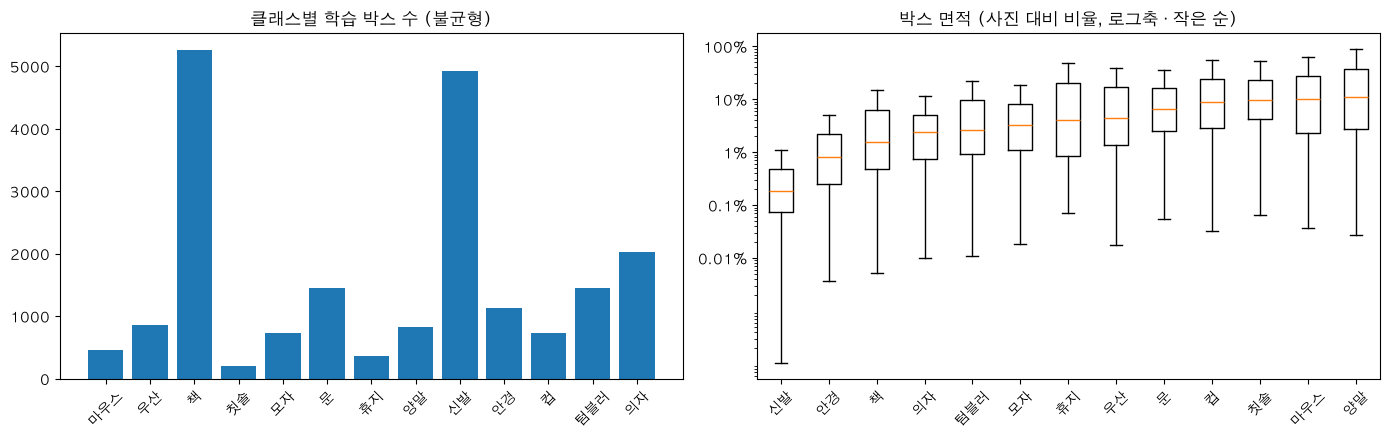

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
s = summary.reset_index()
ax[0].bar(s['클래스'], s['박스_train'], color='tab:blue'); ax[0].set_title('클래스별 학습 박스 수 (불균형)')
ax[0].tick_params(axis='x', rotation=45)
order = tr.groupby('클래스').area.median().sort_values().index      # 면적 중앙값이 작은 순
ax[1].boxplot([tr[tr['클래스'] == k].area for k in order], showfliers=False)
ax[1].set_xticks(range(1, len(order) + 1), order, rotation=45)
ax[1].set_yscale('log'); ax[1].set_yticks([1e-4, 1e-3, 1e-2, 1e-1, 1], ['0.01%', '0.1%', '1%', '10%', '100%'])
ax[1].set_title('박스 면적 (사진 대비 비율, 로그축 · 작은 순)')
plt.tight_layout(); plt.show()

### 사진 예시 — 클래스마다 한 장
초록 박스가 정답 라벨. "가까이 큰 물건 하나"인 앱 장면과 달리, 멀리 작게 찍힌 사진이 많다.

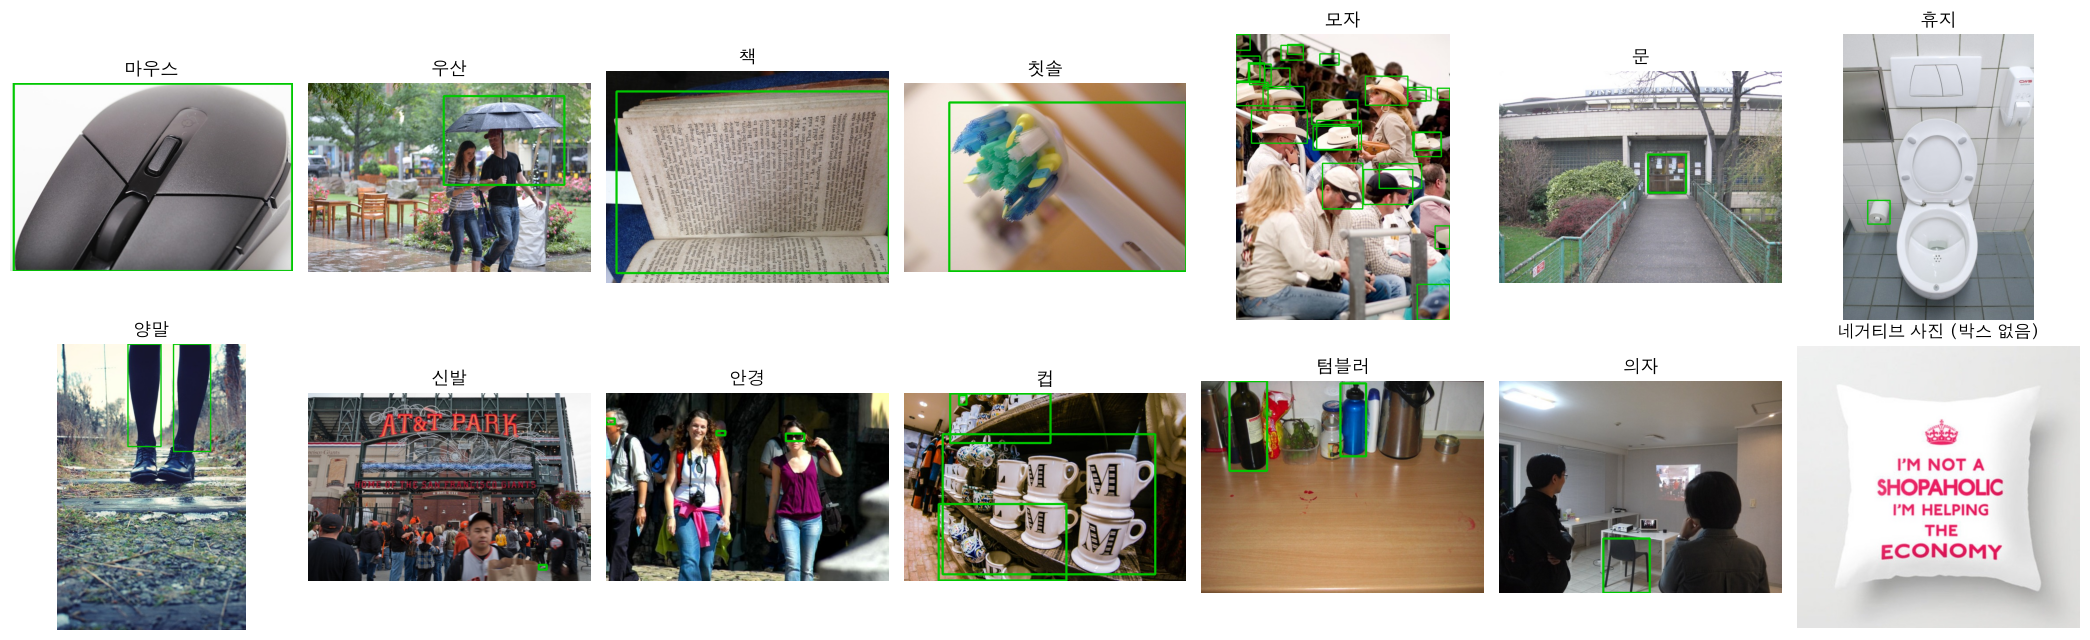

In [5]:
def draw(img_path, rows, color=(0, 200, 0)):
    img = cv2.imread(str(img_path)); H, W = img.shape[:2]
    for r in rows.itertuples():
        x1, y1 = int((r.cx - r.w / 2) * W), int((r.cy - r.h / 2) * H)
        x2, y2 = int((r.cx + r.w / 2) * W), int((r.cy + r.h / 2) * H)
        cv2.rectangle(img, (x1, y1), (x2, y2), color, max(2, W // 200))
    return img[:, :, ::-1]

rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 7, figsize=(21, 6.5)); axes = axes.ravel()
for c in range(13):
    imgs = tr[tr.cls == c].image.unique()
    stem = rng.choice(imgs)
    axes[c].imshow(draw(DATA / 'images/train' / f'{stem}.jpg', tr[(tr.image == stem) & (tr.cls == c)]))
    axes[c].set_title(KO[c], fontsize=13); axes[c].axis('off')
neg = [p for p in (DATA / 'labels/train').glob('*.txt') if not p.read_text().strip()]
stem = rng.choice(neg).stem
axes[13].imshow(cv2.imread(str(DATA / 'images/train' / f'{stem}.jpg'))[:, :, ::-1]); axes[13].set_title('네거티브 사진 (박스 없음)'); axes[13].axis('off')
plt.tight_layout(); plt.show()

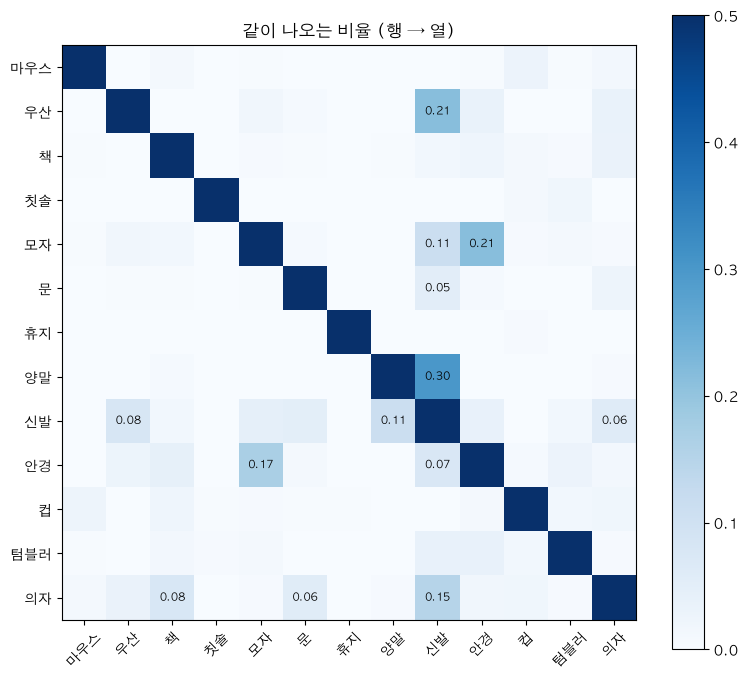

In [6]:
# 한 사진에 같이 나오는 클래스 (행 클래스 사진 중 열 클래스도 있는 비율)
pres = pd.crosstab(tr.image, tr['클래스']).clip(upper=1)[KO]
co = (pres.T @ pres) / pres.sum().values[:, None]
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(co.values, cmap='Blues', vmin=0, vmax=0.5)
ax.set_xticks(range(13), KO, rotation=45); ax.set_yticks(range(13), KO)
for i in range(13):
    for j in range(13):
        if i != j and co.values[i, j] >= 0.05:
            ax.text(j, i, f'{co.values[i, j]:.2f}', ha='center', va='center', fontsize=8)
ax.set_title('같이 나오는 비율 (행 → 열)'); plt.colorbar(im); plt.tight_layout(); plt.show()

### 쟁점 ② — "불균형 때문에 성능이 낮은 거 아냐?" → **아니었다**

A 모델에서 가장 못한 클래스를 보면:

| 클래스 | 박스 수 (A 학습) | A mAP50 | EDA로 본 진짜 원인 (`wakeup_eda.ipynb`) |
|---|---|---|---|
| 📖 책 | **가장 많음** | 0.33 | 박스의 **61%가 '묶음(group-of)' 박스** (책장 전체를 박스 하나로), 76%가 버릴 만한 박스 |
| 👟 신발 | **많음** | 0.42 | 박스 면적 중앙값 **0.3%** — 74%가 아주 작음 (사람 전신 사진의 발) |
| 🚪 문 | 보통 | 0.36 | 대부분 **건물 외벽 사진**의 문 — 집 안 방문과 다름 |
| 🧦 양말 | 적음 | 0.51 | 사진의 30%에 신발도 같이 나옴 (양말↔신발 헷갈림) |
| 🖱️ 마우스 | 적음 | 0.87 | 사진이 깨끗함 (책상 위 마우스 하나) |

→ 박스가 **가장 많은** 책·신발이 **가장 못한다**. 문제는 양이 아니라 **질(라벨이 어떤 장면인가)**.
그래서 "증강·가중치로 불균형 맞추기" 대신 **"데이터 정제(C)"**와 **"앱 장면으로 잘라 학습(E)"**을 시도했다.

## 5. 원리 — YOLO11n · 전이학습 · 지표

### YOLO11n 구조
```
입력 320×320×3
 └ 백본 (Conv · C3k2 · SPPF · C2PSA)  ← 특징 뽑기. COCO로 배운 "물체 보는 눈"
    └ 넥 PAN-FPN                      ← 큰 특징·작은 특징 섞기 (작은 물체·큰 물체 둘 다)
       └ Detect 헤드 (3가지 크기: 40×40, 20×20, 10×10 격자 = 2100칸)
          ├ 박스 갈래: 칸마다 (cx, cy, w, h)  ← DFL(분포로 경계 예측)
          └ 클래스 갈래: 칸마다 클래스 13개 점수 (각각 sigmoid)
출력 [1, 4+13, 2100] = [1, 17, 2100]
```

### 전이학습 — 무엇이 새로 초기화되나
- COCO 80종 → 우리 13종으로 클래스 수가 바뀌면 **클래스 갈래 마지막 층(80 → 13채널)만 새로 초기화**된다. 백본·넥·박스 갈래는 COCO 가중치 그대로 시작.
- 그래서 "새 6종만 학습시켜서 원래 4종을 잊는지 보기"는 의미가 없다 — 클래스 층이 새로 생기므로 원래 4종은 *잊은 게 아니라 배운 적이 없는 것*. → 실험 B를 **백본 고정(freeze)** 실험으로 바꾼 이유.

### softmax vs sigmoid — 왜 탐지가 "아무것도 없음"을 말할 수 있나

In [7]:
logits = np.array([-3.0, -2.5, -3.2])        # 빈 벽을 봤을 때: 세 클래스 모두 낮은 점수
softmax = np.exp(logits) / np.exp(logits).sum()
sigmoid = 1 / (1 + np.exp(-logits))
pd.DataFrame({'logit': logits, 'softmax (분류기)': softmax.round(3), 'sigmoid (YOLO)': sigmoid.round(3)},
             index=['마우스', '컵', '책'])

,logit,softmax (분류기),sigmoid (YOLO)
마우스,-3.0,0.288,0.047
컵,-2.5,0.475,0.076
책,-3.2,0.236,0.039


- softmax는 합이 1이라 **빈 벽에도 "컵 40%"** 같은 답을 낸다. sigmoid는 클래스마다 독립이라 **모두 5% 미만 → 통과 없음**.
- 대신 sigmoid는 기준값(conf)을 정해야 한다. 이 기준을 **클래스마다 다르게** 고른 게 실험 E의 핵심 중 하나.

### 지표 정리
| 지표 | 뜻 |
|---|---|
| Precision (정밀도) | 모델이 "컵"이라 한 것 중 진짜 컵 비율 |
| Recall (재현율) | 진짜 컵 중 모델이 찾은 비율 |
| F1 | P와 R의 조화평균 |
| mAP50 | 박스가 정답과 50% 이상 겹치면 정답으로 보고, 기준값을 바꿔 가며 P-R 곡선 아래 넓이 → 클래스 평균 |
| **미션 통과율** | 물건 crop을 앱 규칙(틀 안 · 긴 변 ≥ 40% · 가장 큰 박스 · 기준 이상)으로 판정해 **목표 클래스면 통과** |
| **잘못 통과율** | 네거티브 crop(리모컨·휴대폰 등)이 **어떤 미션이든** 통과돼 버린 비율 |

### 후처리 — 2100칸 → 박스 몇 개
1. **decode**: 칸마다 가장 높은 클래스 점수 ≥ 기준이면 박스 후보
2. **NMS**: 같은 클래스끼리 IoU ≥ 0.45로 겹치면 점수 높은 것만 남김
3. **pick_main**: 긴 변이 틀의 40% 이상인 박스 중 **가장 큰 것** = 주인공
4. **연속 0.5초** 주인공이 미션 클래스면 알람 해제

이 4단계를 **파이썬(`src/postprocess.py`)과 JS(`docs/postprocess.js`)로 똑같이** 짜고 양쪽 테스트로 맞췄다. 아래는 실제 앱 모델로 한 장을 처리한 모습.

In [8]:
import onnxruntime as ort
sess = ort.InferenceSession(str(ROOT / 'docs/model.onnx'))
app_conf = {c['id']: c['conf'] for c in json.loads(re.search(r'export const CLASSES = (\[.*?\]);', (ROOT / 'docs/classes.js').read_text(), re.S).group(1))}

def run_app(img_bgr):
    # 앱과 같은 순서: 320으로 → RGB 0~1 → 추론 → decode(가장 낮은 기준) → NMS → 클래스별 기준 → 주인공
    x = cv2.resize(img_bgr, (320, 320), interpolation=cv2.INTER_AREA)[:, :, ::-1].astype(np.float32) / 255
    out = sess.run(None, {sess.get_inputs()[0].name: x.transpose(2, 0, 1)[None].copy()})[0]
    dets = nms(decode(out, min(app_conf.values()), 320), 0.45)
    dets = [d for d in dets if d['score'] >= app_conf[d['cls']]]
    return out, dets, pick_main(dets, 320, 0.4)

pos = pd.read_csv(ROOT / 'data/eval13/pos_crops.csv')
r = pos[(pos.target == 10) & (pos.half == 'test')].iloc[0]
img = cv2.imread(str(ROOT / 'data/eval13/images/pos' / r.file))
out, dets, main = run_app(img)
print('ONNX 출력 모양:', out.shape, '→ 박스 4 + 클래스 13, 2100칸')
print('기준 넘은 칸 수(NMS 전):', int((out[0, 4:].max(0) >= min(app_conf.values())).sum()), '→ NMS 뒤 박스', len(dets), '개')
print('주인공:', KO[main['cls']] if main else '없음', f"({main['score']:.2f})" if main else '')

ONNX 출력 모양: (1, 17, 2100) → 박스 4 + 클래스 13, 2100칸
기준 넘은 칸 수(NMS 전): 1 → NMS 뒤 박스 1 개
주인공: 휴지 (0.42)


## 6. 전체 파이프라인

```
[데이터]  Open Images V7 ──FiftyOne──▶ 클래스별 받기 (13종 + 네거티브 16라벨)
            │  계층 라벨 합치기 · 중복 박스 제거 · YOLO 형식 내보내기
            ▼
[가공]    전체 사진 (긴 변 640)  +  앱 장면 crop (물건 중심 정사각형, 물건이 60% 차지)
            │                       + 네거티브 crop (리모컨·휴대폰·손…)
            ▼
[학습]    yolo11n.pt (COCO) ─▶ A 가중치에서 이어 학습(E) · imgsz 320 · 35에폭 · 맥 MPS
            ▼
[평가]    ① val mAP50 / P / R / F1   ② 미션 통과율 (양성 crop)   ③ 잘못 통과율 (네거티브 crop)
            │  tune 절반으로 클래스별 기준 고르기 (잘못 통과 ≤ 2%) → test 절반으로 재기
            ▼
[내보내기] best.pt ─export─▶ model.onnx (320, opset 12) ─▶ 파이썬 ONNX == ultralytics 확인
            ▼
[앱]      GitHub Pages (HTTPS) ─▶ 아이폰 Safari: 카메라 → 틀 자르기 → onnxruntime-web(wasm)
                                     → decode · NMS · 클래스별 기준 · 주인공 · 0.5초 연속 → 알람 해제
```

## 7. 실험 여정 — 왜 이 순서로 했나

| 실험 | 질문 (가설) | 한 일 | 결과 한 줄 |
|---|---|---|---|
| 기준선 | 튜닝 없이 COCO YOLO로 되나? | COCO 모델 그대로, 원래 아는 4종만 평가 | 책 0.04 — **튜닝 필요** |
| **A** | 전체를 미세조정하면? | 모든 층 학습, 10종, 640 | val mAP50 **0.634** → 앱 v1 |
| B | 백본을 얼리면 빠르고 덜 잊나? | `freeze=10` (넥·헤드만) | 0.589, 1.5배 빠름. 정확도는 A가 위 |
| C | 지저분한 박스를 지우면 나아지나? | 묶음·작은 박스를 회색으로 칠해 학습 | 평가가 깨끗하면 +, 학습엔 **−** → 채택 안 함 |
| **E** | "뭐든 마우스"를 고치려면? | 하드 네거티브 + 앱 장면 crop + 320 + 클래스별 기준 + 3종 추가 | 마우스 잘못 통과 **0.09 → 0.01** → 앱 v2 |

### 학습 곡선 (각 실험의 `results.csv`)

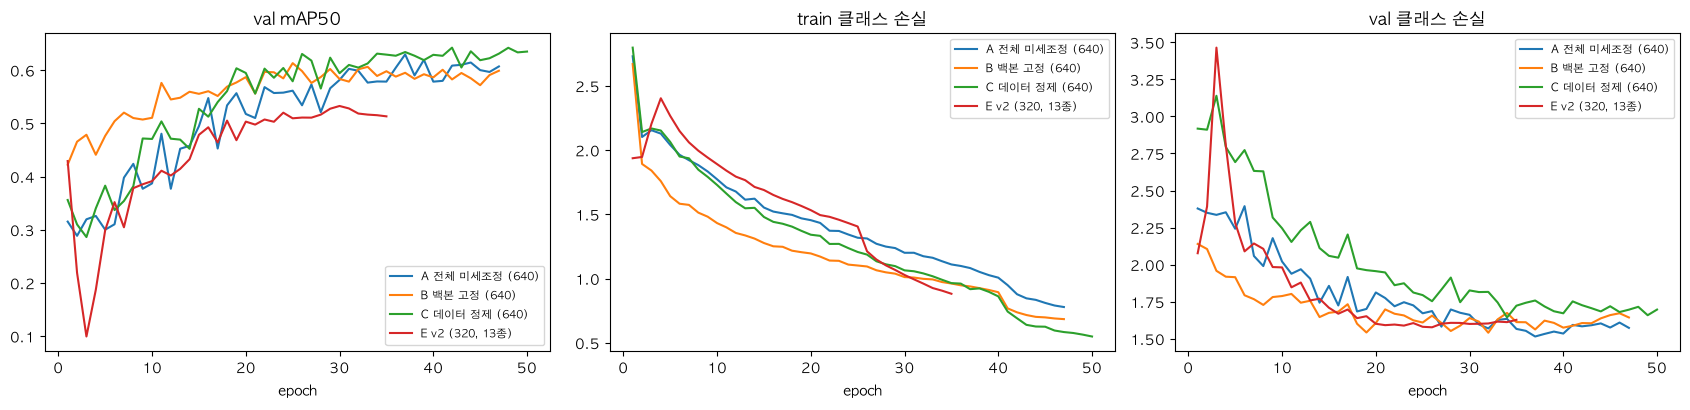

,에폭,최고에폭,학습중_최고_val_mAP50,학습시간_분
실험,,,,
A 전체 미세조정 (640),47,37,0.630,115
B 백본 고정 (640),47,25,0.613,77
C 데이터 정제 (640),50,42,0.642,112
"E v2 (320, 13종)",35,30,0.533,124


주의: 학습 중 val은 실험마다 다르다 — C는 정제한 val, E는 320 크기 · 13종 val. 표의 A 0.634 · B 0.589는 학습 뒤 best.pt를 같은 10종 원본 val로 다시 잰 값.
E는 320 크기 · 13종 val이라 A/B/C(640 · 10종)와 mAP를 그대로 비교하면 안 된다. 같은 조건(10종 val, 320)에서는 A 0.573 vs E 0.577.


In [9]:
runs = {'A 전체 미세조정 (640)': 'A_full', 'B 백본 고정 (640)': 'B_freeze10', 'C 데이터 정제 (640)': 'C_clean', 'E v2 (320, 13종)': 'E_v2'}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
rows = []
for name, d in runs.items():
    df = pd.read_csv(RUNS / d / 'results.csv'); df.columns = df.columns.str.strip()
    ax[0].plot(df.epoch, df['metrics/mAP50(B)'], label=name)
    ax[1].plot(df.epoch, df['train/cls_loss'], label=name)
    ax[2].plot(df.epoch, df['val/cls_loss'], label=name)
    b = df.loc[df['metrics/mAP50(B)'].idxmax()]
    rows.append(dict(실험=name, 에폭=len(df), 최고에폭=int(b.epoch), 학습중_최고_val_mAP50=round(b['metrics/mAP50(B)'], 3),
                     학습시간_분=round(df.time.iloc[-1] / 60)))
for a, t in zip(ax, ['val mAP50', 'train 클래스 손실', 'val 클래스 손실']):
    a.set_title(t); a.set_xlabel('epoch'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index('실험'))
print('주의: 학습 중 val은 실험마다 다르다 — C는 정제한 val, E는 320 크기 · 13종 val. 표의 A 0.634 · B 0.589는 학습 뒤 best.pt를 같은 10종 원본 val로 다시 잰 값.')
print('E는 320 크기 · 13종 val이라 A/B/C(640 · 10종)와 mAP를 그대로 비교하면 안 된다. 같은 조건(10종 val, 320)에서는 A 0.573 vs E 0.577.')

### 7-1. 기준선 vs A vs B — 튜닝하면 원래 알던 4종이 나빠지나?

| 클래스 (COCO가 원래 앎) | 기준선 (COCO 그대로) | A 전체 | B 백본 고정 |
|---|---|---|---|
| 🖱️ 마우스 | 0.853 | 0.898 | **0.948** |
| ☂️ 우산 | 0.652 | **0.722** | 0.608 |
| 📖 책 | 0.036 | **0.334** | 0.314 |
| 🪥 칫솔 | 0.487 | **0.837** | 0.801 |
| **10종 전체 val mAP50** | – | **0.634** (1시간 55분) | 0.589 (1시간 18분) |

- **잊지 않았다** — 오히려 올랐다. COCO의 "책"은 사람이 든 책 위주인데 Open Images의 책 사진에 맞춰졌기 때문.
- B(백본 고정)는 빠르지만 새 6종을 덜 배운다 → **A를 앱 v1으로**.

### 7-2. 쟁점 ③ — "그냥 COCO YOLO 쓰면 안 돼?" (튜닝의 가치)

앱 규칙으로 잰 **미션 통과율** (원래 아는 4종):

| | 마우스 | 우산 | 책 | 칫솔 | 4종 전체 |
|---|---|---|---|---|---|
| COCO 그대로 | 0.64 | 0.76 | **0.04** | 0.80 | 0.27 |
| A (튜닝) | **1.00** | **0.80** | **0.56** | 0.67 | **0.65** |

→ 원래 아는 물건조차 튜닝 뒤 2배 이상 잘 통과. 그리고 COCO는 모자·문·휴지·양말·신발·안경을 **아예 모른다**.

### 7-3. 실험 C — 지저분한 박스를 지우면? (2×2 실험)

EDA에서 책의 61%가 묶음 박스, 신발의 74%가 아주 작은 박스였다. "모델이 이상한 박스를 배워서 못한다"는 가설로,
**버릴 박스 자리를 회색(114)으로 칠해** 아예 안 보이게 하고 학습했다 (라벨만 지우면 그 물체를 '배경'으로 배우므로 칠함).

평가 세트도 같은 규칙으로 깨끗하게 만든 버전을 두고 **모델(A/C) × 평가(원본/정제)** 2×2로 나눠 쟀다:

| | val 원본 | val 정제 |
|---|---|---|
| A (원본 학습) | 0.634 | **0.709** |
| C (정제 학습) | 0.508 | 0.634 |

- **평가 효과** (같은 모델, 평가만 깨끗하게): +0.075 → 원래 점수의 일부는 "평가가 지저분해서" 깎인 것.
- **학습 효과** (같은 평가, 학습만 깨끗하게): **−0.074** → 지우면 오히려 손해.
  - 오른 클래스: 모자 +.09, 문 +.08, 신발 +.08 / 내린 클래스: **책 −.35**, 휴지 −.32, 칫솔 −.17
  - 책은 박스의 76%를 지웠더니 배울 게 너무 적어졌다.
- 앱 통과율도 A 0.56 > C 0.50 → **C는 채택 안 함**. 교훈: *정제는 "지울 것"이 아니라 "앱 장면에 맞는 것을 더할 것"*. → 실험 E로.

### 7-4. 실험 E (v2) — "뭐만 해도 마우스로 나와요" 고치기

아이폰에서 써 보니 **리모컨·휴대폰을 비춰도 "마우스"**가 떴다. 원인 진단:

| 원인 | 왜 생겼나 | 처방 |
|---|---|---|
| 모델이 "마우스 아닌 비슷한 것"을 본 적이 없음 | 학습 데이터에 **미션 클래스가 있는 사진만** 있었음 | **하드 네거티브**: 리모컨·휴대폰·시계·헤드폰·손 등 16라벨 사진 1,560장을 박스 없이(=배경으로) 추가 |
| 학습 장면 ≠ 앱 장면 | 학습은 멀리 작게, 앱은 가까이 크게 | **앱 장면 crop**: 물건 중심 정사각형으로 잘라(물건이 60%) 추가 · 학습 크기도 앱과 같은 **320** |
| 모든 클래스에 같은 기준 0.5 | 마우스는 원래 점수가 잘 나오는 클래스 | **클래스별 기준**: 네거티브 tune 절반에서 잘못 통과 ≤ 2%가 되는 가장 낮은 기준 |

추가로 컵·텀블러·의자 3종을 넣고, 약한 문·신발·책은 사진을 1,000장까지 늘렸다.
학습 세트: 전체 사진 7,435 + crop 12,796 = **20,231장**, A 가중치에서 이어 35에폭(약 2.1시간).

**쟁점 ④ — 처음엔 crop을 박스마다 만들었다가 2.8만 장 → 1에폭 7분, 60에폭 7시간.**
사진·클래스마다 가장 큰 박스 하나로 줄여 1.3만 장으로 — 시간 예산과 데이터 양의 거래.

아래는 저장된 평가 crop으로 **지금 앱 모델(E)**을 직접 돌려 보는 셀이다.

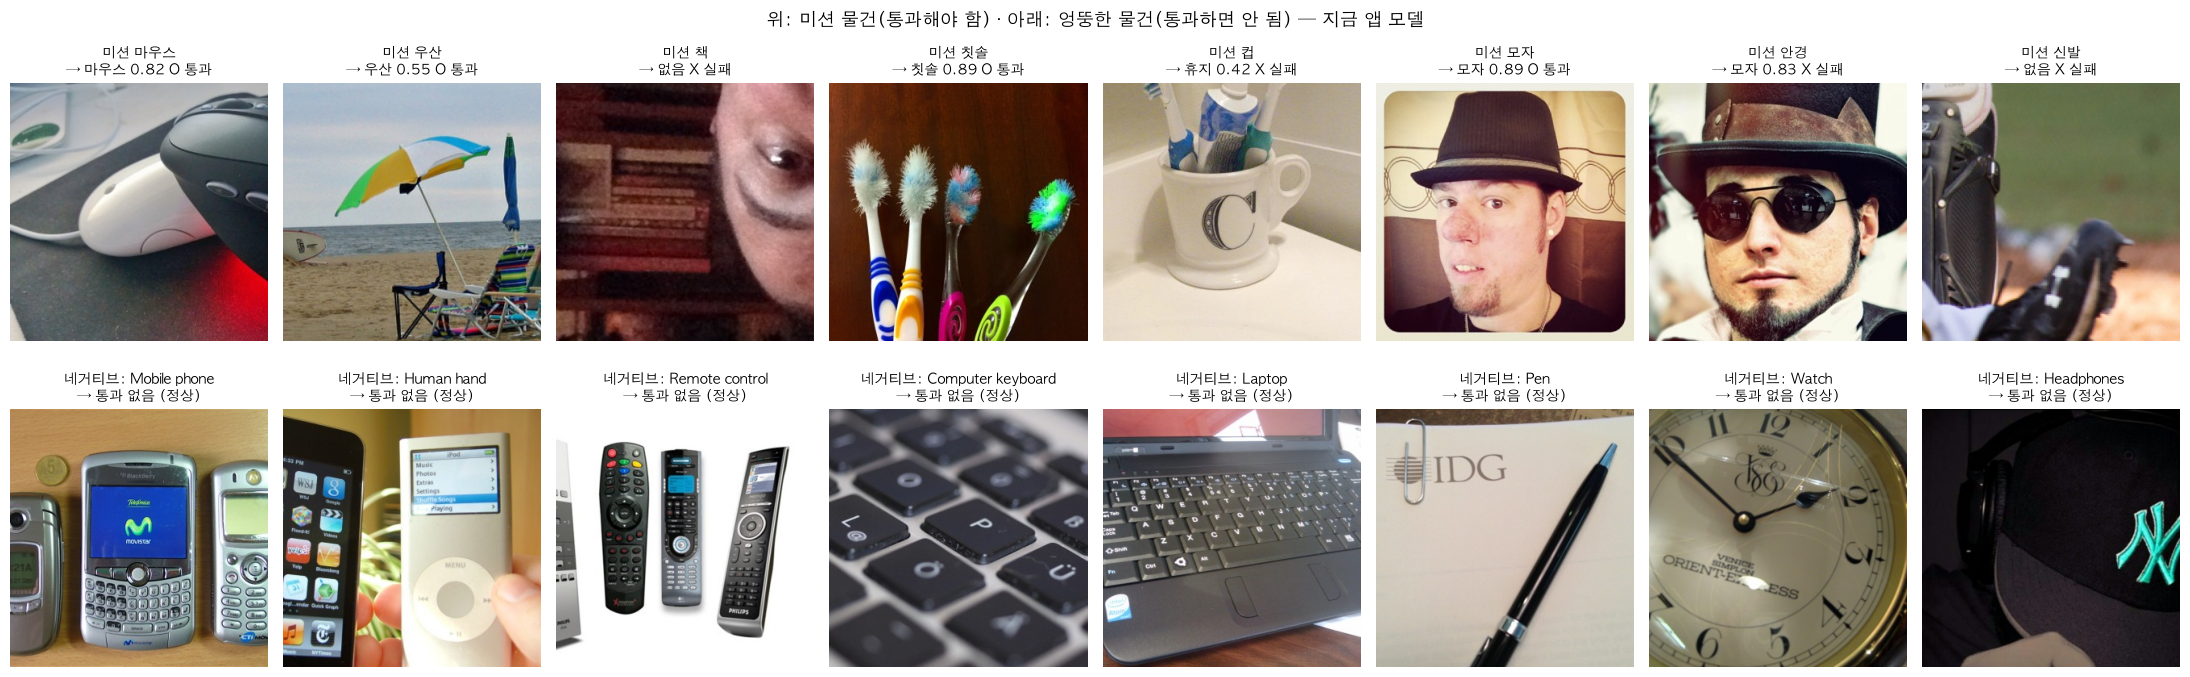

In [10]:
neg = pd.read_csv(ROOT / 'data/eval13/neg_crops.csv')
neg = neg[neg.n_rows == 0]   # 목표 물건이 40% 이상 보이는 네거티브 crop은 제외 (wakeup_v2와 같은 규칙)
pick_pos = pos[pos.half == 'test'].groupby('target').head(1).head(8)
pick_neg = neg[neg.half == 'test'].groupby('center').head(1).head(8)
fig, axes = plt.subplots(2, 8, figsize=(22, 7.2))
for ax, r in zip(axes[0], pick_pos.itertuples()):
    img = cv2.imread(str(ROOT / 'data/eval13/images/pos' / r.file)); _, _, m = run_app(img)
    ok = m is not None and m['cls'] == r.target
    ax.imshow(cv2.resize(img, (320, 320))[:, :, ::-1]); ax.axis('off')
    got = f"{KO[m['cls']]} {m['score']:.2f}" if m else '없음'
    ax.set_title(f"미션 {KO[r.target]}\n→ {got} {'O 통과' if ok else 'X 실패'}", fontsize=10)
for ax, r in zip(axes[1], pick_neg.itertuples()):
    img = cv2.imread(str(ROOT / 'data/eval13/images/neg' / r.file)); _, _, m = run_app(img)
    ax.imshow(cv2.resize(img, (320, 320))[:, :, ::-1]); ax.axis('off')
    ax.set_title(f"네거티브: {r.center}\n→ {'잘못 통과: ' + KO[m['cls']] if m else '통과 없음 (정상)'}", fontsize=10)
plt.suptitle('위: 미션 물건(통과해야 함) · 아래: 엉뚱한 물건(통과하면 안 됨) — 지금 앱 모델', fontsize=13); plt.tight_layout(h_pad=2.5); plt.show()

In [11]:
# 저장된 평가 crop 전체를 지금 앱 모델로 다시 판정 (CPU, 1~2분)
def judge(df, sub):
    res = []
    for r in df.itertuples():
        _, _, m = run_app(cv2.imread(str(ROOT / 'data/eval13/images' / sub / r.file)))
        res.append(-1 if m is None else m['cls'])
    return np.array(res)

pos_t, neg_t = pos[pos.half == 'test'].reset_index(drop=True), neg[neg.half == 'test'].reset_index(drop=True)
pos_pred, neg_pred = judge(pos_t, 'pos'), judge(neg_t, 'neg')
pos_t['통과'] = pos_pred == pos_t.target
by = pos_t.groupby('target').통과.agg(['size', 'mean']).rename(columns={'size': 'crop수', 'mean': '통과율'})
by.index = [KO[i] for i in by.index]
display(by.round(2).T)
print(f'미션 통과율 (13종, test 절반 {len(pos_t)}장): {pos_t.통과.mean():.3f}')
print(f'잘못 통과율 (네거티브 test {len(neg_t)}장): 아무 클래스 {np.mean(neg_pred >= 0):.3f} · 마우스 {np.mean(neg_pred == 0):.3f}')

,마우스,우산,책,칫솔,모자,문,휴지,양말,신발,안경,컵,텀블러,의자
crop수,18.00,14.00,202.00,11.00,104.00,50.00,1.0,17.00,60.00,76.00,68.00,64.00,62.00
통과율,0.94,0.43,0.73,0.91,0.83,0.68,1.0,0.88,0.55,0.46,0.81,0.69,0.47


미션 통과율 (13종, test 절반 747장): 0.687
잘못 통과율 (네거티브 test 209장): 아무 클래스 0.153 · 마우스 0.014


### A vs E — 저장된 결과 (`wakeup_v2.ipynb` 6~7절)

**잘못 통과율** (네거티브 crop 422장, 기준 0.5)

| | A (앱 v1) | E (앱 v2) |
|---|---|---|
| 네거티브가 **마우스**로 통과 | 0.092 | **0.009** |
| 네거티브가 **아무 클래스로든** 통과 | 0.223 | **0.114** |

A가 마우스로 착각한 것: 리모컨의 62%, 휴대폰 29%, 시계 23%, 헤드폰 16% — **"손에 쥐는 작고 매끈한 물건 = 마우스"**로 배웠던 것.

**미션 통과율** (양성 crop, 기준 0.5)

| 클래스 | A | E | | 클래스 | A | E |
|---|---|---|---|---|---|---|
| 🖱️ 마우스 | 1.00 | 0.96 | | 🚪 문 | 0.27 | **0.59** |
| ☂️ 우산 | **0.76** | 0.59 | | 🧻 휴지 (3장뿐) | 0.67 | 1.00 |
| 📖 책 | 0.64 | **0.83** | | 🧦 양말 | 0.76 | 0.76 |
| 🪥 칫솔 | 0.56 | 0.61 | | 👟 신발 | 0.35 | **0.50** |
| 🧢 모자 | 0.76 | **0.81** | | 👓 안경 | **0.68** | 0.51 |
| ☕ 컵 | – | 0.82 | | 🥤 텀블러 | – | 0.66 |
| 🪑 의자 | – | 0.44 | | **기존 10종** | 0.62 | **0.72** |

**클래스별 기준까지 넣은 최종 비교** (test 절반)

| 설정 | 기존 10종 통과율 | 잘못 통과 (아무거나) | 잘못 통과 (마우스) |
|---|---|---|---|
| A · 기준 0.5 (앱 v1) | 0.617 | 0.220 | 0.100 |
| A · 클래스별 기준 | 0.631 | **0.124** | 0.014 |
| E · 기준 0.5 | **0.722** | 0.153 | 0.010 |
| **E · 클래스별 기준 (앱 v2)** | 0.696 | 0.153 | 0.014 |

### 쟁점 ⑤ — 모델을 바꾼 게 효과였나, 기준을 바꾼 게 효과였나?
- **A에 기준만 클래스별로 바꿔도** 마우스 잘못 통과가 0.100 → 0.014 (A의 마우스 기준이 0.90까지 올라감). *기준 조정만으로도 상당 부분 해결.*
- 그래도 E는 같은 수준의 잘못 통과에서 통과율이 **+0.065** 높다 → 네거티브 학습은 "기준을 높이지 않고도 구분"하게 해 줌.
- 교체 규칙을 **실험 전에** 정해 두었다: *잘못 통과가 줄고, 기존 10종 통과율이 0.05보다 많이 떨어지지 않으면 교체.* → 0.220→0.153, 0.617→0.696 로 만족 → 앱 v2 교체.
  (결과를 보고 규칙을 정하면 원하는 결론에 맞춰 고르게 된다)

### 약한 클래스(문·신발·책)의 F1
| 클래스 | 앱 crop F1: A → E | 전체 사진 val F1 (320): A → E |
|---|---|---|
| 🚪 문 | 0.50 → **0.79** | 0.313 → 0.418 |
| 👟 신발 | 0.45 → **0.68** | 0.387 → **0.271** |
| 📖 책 | 0.76 → **0.82** | 0.359 → 0.348 |

→ 앱 장면(crop)에선 셋 다 올랐지만, 전체 사진에선 신발이 내렸다. **앱 장면에 맞춰 학습했으니 앱 장면에서 좋아진 것** — 무엇에 최적화할지를 고른 결과.

## 8. 앱으로 만들기

### 쟁점 ⑥ — 어떻게 아이폰에서 돌리나

| 방법 | 장점 | 단점 | 판단 |
|---|---|---|---|
| 네이티브 iOS (CoreML) | 가장 빠름, 진짜 OS 알람 | Xcode·맥 개발 환경·개발자 계정 필요, 스터디원이 못 돌려 봄 | ✗ |
| 서버 추론 (Flask + GPU) | 큰 모델 가능 | 서버 비용·관리, 매 프레임 업로드 지연 | ✗ |
| **웹앱 + 브라우저 추론** (onnxruntime-web) | 링크 하나로 누구나 실행, 서버 없음(GitHub Pages 무료), 사진이 폰 밖으로 안 나감 | 화면을 켜 둬야 알람 울림(웹 제약), wasm이라 네이티브보다 느림 | ✅ **채택** |

### 앱 구조 (`docs/`, 프레임워크 없음)
- `index.html` · `style.css` · `app.js` — 화면·카메라·알람
- `postprocess.js` — decode · NMS · pick_main · 연속 판정 (**파이썬 `src/postprocess.py`와 같은 동작, node 테스트로 확인**)
- `classes.js` — 13종 이름·이모지·**클래스별 기준** (`src/config.py`에서 생성)
- `model.onnx` — 10.5MB, 출력 [1, 17, 2100]

### 실제로 부딪힌 문제들 (폰에서 돌려 봐야 아는 것)
| 문제 | 원인 | 해결 |
|---|---|---|
| 스캔 틀이 화면 밖으로 밀림 | 카메라는 가로 영상, 화면은 세로 → `object-fit: cover`로 잘린 부분 | **화면에 보이는 영역** 기준으로 틀 계산 |
| 무음 모드에서 알람 소리 안 남 | iOS 무음 스위치 | `navigator.audioSession.type = 'playback'`, 탭할 때 오디오 깨우기 |
| 얇은 물건(칫솔·안경) 통과 못 함 | 처음 규칙이 "박스 면적 ≥ 틀의 15%" | **"긴 변 ≥ 틀의 40%"**로 변경 |
| 프레임 한두 장 놓치면 진행 바가 0으로 | 연속 0.5초 판정이 너무 엄격 | 프레임 시간 기반 **유예(grace)** |
| 우산 미션에 모자 → "그건 모자가 아니잖아요!" | 문구에 잡힌 물건 이름을 넣음 | "그건 **우산이** 아니라 **모자예요**!" (받침 따라 이/가·이에요/예요) |
| 화면이 꺼짐 | 폰 자동 잠금 | Wake Lock API |

In [12]:
# 앱이 실제로 쓰는 클래스별 기준 (docs/classes.js)
pd.DataFrame([dict(클래스=f'{C.CLASSES13[i].emoji} {KO[i]}', 기준=v) for i, v in app_conf.items()]).set_index('클래스').T

클래스,🖱️ 마우스,☂️ 우산,📖 책,🪥 칫솔,🧢 모자,🚪 문,🧻 휴지,🧦 양말,👟 신발,👓 안경,☕ 컵,🥤 텀블러,🪑 의자
기준,0.4,0.4,0.65,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.5,0.4


In [13]:
# 앱의 판정 루프 핵심 (docs/app.js에서 발췌)
src = (ROOT / 'docs/app.js').read_text()
i = src.find('async function loop')
print(src[i: src.find('\n}\n', i) + 2])

async function loop() {
  if (!running) return;
  if (video.readyState >= 2 && video.videoWidth > 0) {
    try {
      const t0 = performance.now();
      const out = await session.run({ [session.inputNames[0]]: toTensor() });
      if (!running) return;
      const dt = performance.now() - t0;
      avgFrameMs = avgFrameMs ? 0.8 * avgFrameMs + 0.2 * dt : dt;
      const o = out[session.outputNames[0]], [, ch, n] = o.dims;     // [1, 4+nc, n]
      const dets = applyConf(nms(decode(o.data, ch - 4, n, DECODE_CONF, INPUT), IOU), CLASSES, CONF);
      const main = pickMain(dets, INPUT, MIN_SIDE);
      // 느린 기기에서도 한 프레임은 놓쳐도 되게: grace ≥ 2.5 × 프레임 시간
      const grace = Math.max(GRACE_MS, 2.5 * avgFrameMs);
      const progress = streak.update(main !== null && main.cls === mission.id, performance.now(), grace);
      $('message').textContent = main && main.cls !== mission.id && CLASSES[main.cls] ? notText(mission, CLASSES[main.cls]) : '';
      draw(dets, main, progress);
      if (progres

## 9. 결과 한눈에 · 한계 · 다음 할 일

### 한 줄 요약
> **COCO YOLO11n을 Open Images 13종으로 파인튜닝**하고, **하드 네거티브 + 앱 장면 crop + 클래스별 기준**으로
> "뭐든 마우스" 잘못 통과를 **9% → 1%**, 미션 통과율을 **0.62 → 0.70**으로 바꿔 아이폰 웹앱에 올렸다.

| 단계 | 핵심 숫자 |
|---|---|
| 기준선 (COCO 그대로) | 4종 통과율 0.27, 6종은 아예 모름 |
| A (앱 v1) | val mAP50 0.634, 10종 통과율 0.62, 잘못 통과 0.22 (마우스 0.09) |
| C (정제) | 학습 효과 −0.074 → 채택 안 함 |
| **E (앱 v2)** | 10종 통과율 0.70, 잘못 통과 0.15 (마우스 0.01), 13종 |

### 한계 (정직하게)
- 모든 숫자는 **Open Images 사진을 잘라서** 잰 것. 진짜 폰 카메라 화면(흔들림·조명·초점)과 다르다 → **직접 찍은 사진 테스트**가 아직 없다.
- 표본이 작은 클래스: 휴지(평가 crop 3장), 칫솔(18), 마우스(23), 양말(25) → 몇 장에 크게 흔들림.
- 휴지 = Open Images의 'Toilet paper'(두루마리)만. 한국에서 '휴지'라 부르는 각티슈·물티슈는 안 배움.
- 텀블러 = 실제로는 'Bottle'(물병) 라벨.
- 우산·안경은 v2에서 오히려 내렸다. 의자는 0.44로 약하다.
- 학습 초반 mAP가 0.43 → 0.10으로 출렁 — warm start에 학습률 0.01이 큰 것으로 보임 (`lr0`를 낮춘 실험은 안 함).

### 다음 할 일
1. 직접 찍은 사진 `my_photos/<클래스>/` 클래스당 10~20장 → 진짜 통과율
2. 휴지에 `Facial tissue holder`(각티슈)·`Paper towel`(키친타올) 합치기
3. 우산·안경·의자 보강 (앱 장면 crop을 더, 또는 클래스별 기준 다시 고르기)
4. warm start 학습률 낮추기 (`lr0=0.001`)

## 10. 스터디 토론 질문

1. **분류 vs 탐지**: 이 앱을 ResNet 분류기로 만든다면, "빈 벽"이나 "엉뚱한 물건"은 어떻게 처리할 수 있을까? (힌트: "기타" 클래스, 확률 기준, sigmoid)
2. **불균형**: 박스가 가장 많은 책이 가장 못했다. 그럼 클래스 가중치·오버샘플링은 언제 효과가 있을까?
3. **실험 C의 교훈**: 지저분한 라벨을 *지우는* 것과 *좋은 데이터를 더하는* 것 — 각각 언제 맞을까?
4. **지표 선택**: mAP는 내렸는데(신발 전체 사진 F1 ↓) 앱 통과율은 올랐다. 무엇을 기준으로 "모델이 좋아졌다"고 해야 할까?
5. **기준 vs 모델**: 기준값 조정만으로 "뭐든 마우스"의 대부분이 해결됐다. 그럼 재학습은 언제 필요할까?
6. **실험 전에 교체 규칙 정하기**: 왜 결과를 보기 *전에* 정해야 할까?
7. **다음 클래스를 추가한다면** (예: 리모컨 미션) — 지금 리모컨은 네거티브인데, 어떻게 바꿔야 할까?